In [1]:
import sys
import h5py
import numpy as np
import scipy
import matplotlib.pyplot as plt
import healpy as hp

%matplotlib inline

NSIDE = 32
print(
    "Approximate resolution at NSIDE {} is {:.2} deg".format(
        NSIDE, hp.nside2resol(NSIDE, arcmin=True) / 60
    )
)

NPIX = hp.nside2npix(NSIDE)
print(NPIX)
   
m = np.arange(NPIX)
hp.mollview(m, title="Mollview image RING")
hp.graticule()

In [2]:
filename = ( '/data/wiay/gw-data-releases/2026/19500064/'
    'samples-rpo4ab-1366933504-55469568-clipped.hdf') #shorthand to make finding the data easier, long path is a pain to work with 

Processed 10,000 / 2,959,534 rows
Processed 20,000 / 2,959,534 rows
Processed 30,000 / 2,959,534 rows
Processed 40,000 / 2,959,534 rows
Processed 50,000 / 2,959,534 rows
Processed 60,000 / 2,959,534 rows
Processed 70,000 / 2,959,534 rows
Processed 80,000 / 2,959,534 rows
Processed 90,000 / 2,959,534 rows
Processed 100,000 / 2,959,534 rows
Processed 110,000 / 2,959,534 rows
Processed 120,000 / 2,959,534 rows
Processed 130,000 / 2,959,534 rows
Processed 140,000 / 2,959,534 rows
Processed 150,000 / 2,959,534 rows
Processed 160,000 / 2,959,534 rows
Processed 170,000 / 2,959,534 rows
Processed 180,000 / 2,959,534 rows
Processed 190,000 / 2,959,534 rows
Processed 200,000 / 2,959,534 rows
Processed 210,000 / 2,959,534 rows
Processed 220,000 / 2,959,534 rows
Processed 230,000 / 2,959,534 rows
Processed 240,000 / 2,959,534 rows
Processed 250,000 / 2,959,534 rows
Processed 260,000 / 2,959,534 rows
Processed 270,000 / 2,959,534 rows
Processed 280,000 / 2,959,534 rows
Processed 290,000 / 2,959,534

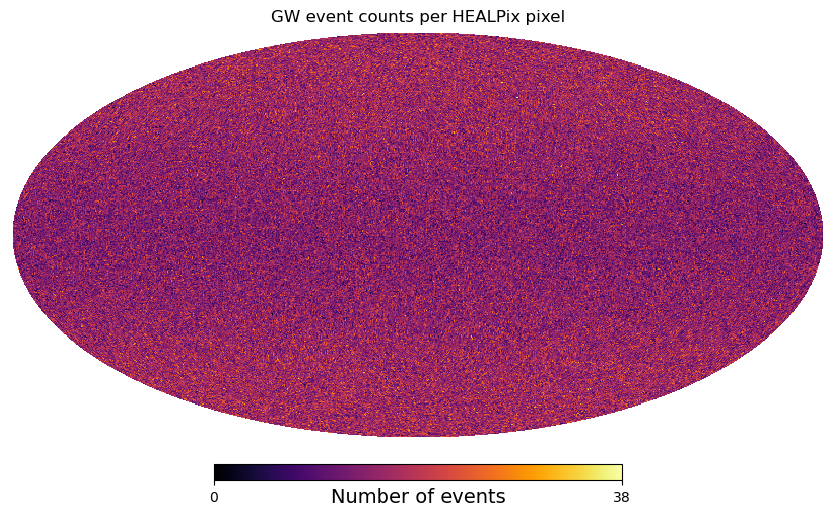

In [3]:
nside = 128 #mediocre number of pixels, good for first pass but I'd like to increase as the project continues 
npix = hp.nside2npix(nside) # this gives the number of pixels on the map (far as i can tell)
chunk_size = 10_000 #everything I tried last week was taking too long so im splitting it into chunks to make it more manageable

counts = np.zeros(npix, dtype=np.int64) #this line makes an empty array of pixels that will update as events fall into them, which i can call on later once its full 

with h5py.File(filename, 'r') as f:  #reading in the file and making sure I dont read every row at once and blow up my computer
    events = f['events'] #shorthand again
    n_events = len(events) # defining number of events

    for start in range(0, n_events, chunk_size): #making sure it only goes one chunk at a time 
        stop = min(start + chunk_size, n_events)

        ra = events['right_ascension'][start:stop] #defining what columns to look at  
        dec = events['declination'][start:stop]

        valid = np.isfinite(ra) & np.isfinite(dec) #this just checks that the coordinate isnt nonsense
        ra = ra[valid]
        dec = dec[valid]

        ra_deg = np.rad2deg(ra) #converting radians to degrees (documentation says its given in radians so needs changed for Healpy)
        dec_deg = np.rad2deg(dec)

        pixels = hp.ang2pix( #this is changing these coordinates into pixel information so healpy knows how to plot it, using nside and my coordinates
            nside,
            ra_deg,
            dec_deg,
            lonlat=True
        )    

        counts += np.bincount( #sums all the chunks 
            pixels,
            minlength=npix
        )

        print(f'Processed {stop:,} / {n_events:,} rows') #this looks like a sanity check 


hp.mollview(
    counts,
    title='GW event counts per HEALPix pixel',
    unit='Number of events',
    cmap='inferno'
)
plt.show()


Chunk 0–10,000: mean SNR = 10.717, valid injections = 4,871
Chunk 10,000–20,000: mean SNR = 10.935, valid injections = 7,290
Chunk 20,000–30,000: mean SNR = 10.845, valid injections = 7,408
Chunk 30,000–40,000: mean SNR = 11.007, valid injections = 5,861
Chunk 40,000–50,000: mean SNR = 10.858, valid injections = 7,026
Chunk 50,000–60,000: mean SNR = 10.912, valid injections = 6,754
Chunk 60,000–70,000: mean SNR = 10.955, valid injections = 6,719
Chunk 70,000–80,000: mean SNR = 10.888, valid injections = 7,420
Chunk 80,000–90,000: mean SNR = 11.139, valid injections = 7,695
Chunk 90,000–100,000: mean SNR = 10.991, valid injections = 7,964
Chunk 100,000–110,000: mean SNR = 10.948, valid injections = 6,835
Chunk 110,000–120,000: mean SNR = 10.926, valid injections = 6,283
Chunk 120,000–130,000: mean SNR = 10.788, valid injections = 6,142
Chunk 130,000–140,000: mean SNR = 10.847, valid injections = 6,052
Chunk 140,000–150,000: mean SNR = 10.914, valid injections = 5,696
Chunk 150,000–160,0

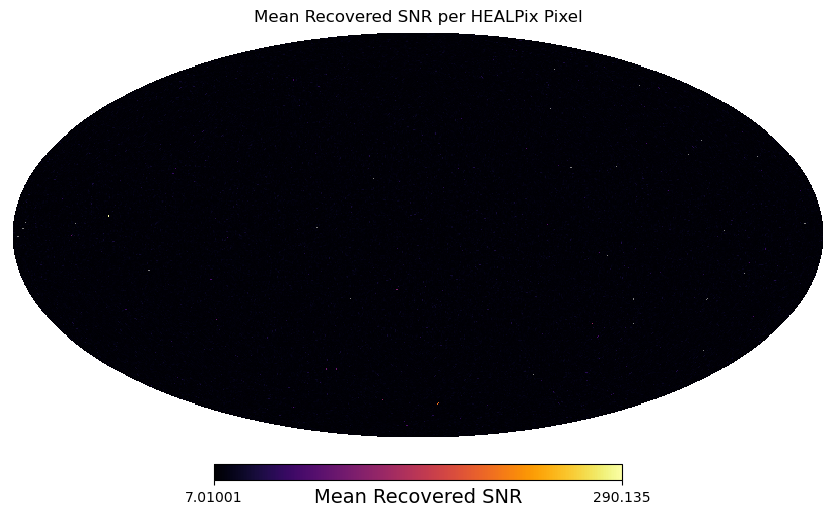

In [4]:
nside = 128 #mediocre number of pixels, good for first pass but I'd like to increase as the project continues 
npix = hp.nside2npix(nside) # this gives the number of pixels on the map (far as i can tell)
chunk_size = 10_000 #everything I tried last week was taking too long so im splitting it into chunks to make it more manageable

snr_sum = np.zeros(npix, dtype=np.float64)
snr_count = np.zeros(npix, dtype=np.int64) #this line makes an empty array of pixels that will update as events fall into them, which i can call on later once its full 



with h5py.File(filename, 'r') as f:  #reading in the file and making sure I dont read every row at once and blow up my computer
    events = f['events'] #shorthand again
    n_events = len(events) # defining number of events

    for start in range(0, n_events, chunk_size): #making sure it only goes one chunk at a time 
        stop = min(start + chunk_size, n_events)

        ra = events['right_ascension'][start:stop] #defining what columns to look at  
        dec = events['declination'][start:stop]
        snr = events['gstlal_rec_snr_net'][start:stop]

        valid = np.isfinite(ra) & np.isfinite(dec) & np.isfinite(snr) #this just checks that the coordinate isnt nonsense
        ra = ra[valid]
        dec = dec[valid]
        snr = snr[valid]

        chunk_mean_snr = np.mean(snr) if len(snr) > 0 else np.nan
        
        print(
            f"Chunk {start:,}–{stop:,}: "
            f"mean SNR = {chunk_mean_snr:.3f}, "
            f"valid injections = {len(snr):,}"
    )

        ra_deg = np.rad2deg(ra) #converting radians to degrees (documentation says its given in radians so needs changed for Healpy)
        dec_deg = np.rad2deg(dec)

        pixels = hp.ang2pix( #this is changing these coordinates into pixel information so healpy knows how to plot it, using nside and my coordinates
            nside,
            ra_deg,
            dec_deg,
            lonlat=True
        )    

        snr_sum += np.bincount( #totals the SNR per pixel 
            pixels,
            weights = snr,
            minlength = npix
    )

        snr_count += np.bincount( #this counts the number of injections per pixel 
        pixels,
        minlength=npix
    )

mean_snr = np.divide( #uses previous 2 lines of code to find the mean per pixel 
    snr_sum,
    snr_count,
    out=np.full(npix, np.nan),
    where=snr_count > 0
)

mean_snr_plot = mean_snr.copy()
mean_snr_plot[snr_count == 0] = hp.UNSEEN #deals with any invalid SNR values 


hp.mollview(
    mean_snr_plot,
    title='Mean Recovered SNR per HEALPix Pixel',
    unit='Mean Recovered SNR',
    cmap='inferno'
)

plt.show()
